# A classification algorithm: *k*-Nearest Neighbors

![](images/KnnClassification.svg)

The test sample should be classified to blue squares or red triangles. Which one is it? For $k=3$, it's red; for $k=5$, it's blue.

Image from: [Wikipedia](https://upload.wikimedia.org/wikipedia/commons/e/e7/KnnClassification.svg)

## The *k*-NN algorithm

- Assumption: similar inputs have similar outputs.
- Rule: for a test input $\mathbf{x}$, assign the most common label among its $k$ most similar -- "nearest" -- training inputs.
- Tie-breaking tip: if there's a draw, fall back to $k$-NN with a smaller $k$.

## How to measure distance?

- The distance measure (or metric) decides the performance of *k*-NN classifier.
- A common choice is the Minkowski distance of order $p$: $\text{dist}(\mathbf{x},\mathbf{z}) = \left( \sum\limits_{r = 1}^{d}|x_{r} - z_{r}|^{p} \right)^{1/p}$ (in $d$ dimensions)
  - $p = 1$: Manhattan distance
  - $p = 2$: Euclidean distance

### Best constant predictor

- A baseline classifier we should always be able to beat.
- The constant classifier always predicts the same value, regardless of the input.
  - For classification, the best constant is the most common label in the training set.
  - This is also what $k$-NN reduces to when $k = n$.

## An example

![](images/iris.png)

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8-talk")
plt.rcParams['figure.dpi'] = 75



Matplotlib is building the font cache; this may take a moment.


## IMPORTANT

- Always carefully study the data -- always! 
- Not only its statistical properties, but 
    - how it was collected; 
    - was it ethically done? (from whom the data came)
    - were the collectors biased? 
        - can be from scientific side like them having a favorite theory for whose support the data were collected
        - or, from societal side. the latter can be more insidious.

In [ ]:
iris_dataset = load_iris()

# print(iris_dataset)
for key in iris_dataset.keys():
    print(key + "\n", iris_dataset[key])
    # break

data
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    iris_dataset["data"], iris_dataset["target"], test_size=.25, random_state=0)

print(len(X_train))
print(len(X_test))
print(len(y_train))
print(len(y_test))
print(X_train[:5])
print(y_train[:5])

112
38
112
38
[[5.9 3.  4.2 1.5]
 [5.8 2.6 4.  1.2]
 [6.8 3.  5.5 2.1]
 [4.7 3.2 1.3 0.2]
 [6.9 3.1 5.1 2.3]]
[1 1 2 0 2]


In [4]:
# Visual exploration. Important step in data analysis and ML!

name_map =  {0:'setosa', 1:'versicolor', 2:'virginica'}

# make pandas dataframes
iris_train = pd.DataFrame(X_train, columns=iris_dataset.feature_names)
iris_test = pd.DataFrame(X_test, columns=iris_dataset.feature_names)

# see the raw data, a bit more meaningfully
iris_train['Label']=pd.Series(y_train).map(name_map) # Add actual labels after converting them from numerical ones. I've used the data description from the last cell to get this information.
iris_train

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Label
0,5.9,3.0,4.2,1.5,versicolor
1,5.8,2.6,4.0,1.2,versicolor
2,6.8,3.0,5.5,2.1,virginica
3,4.7,3.2,1.3,0.2,setosa
4,6.9,3.1,5.1,2.3,virginica
...,...,...,...,...,...
107,4.9,3.1,1.5,0.1,setosa
108,6.3,2.9,5.6,1.8,virginica
109,5.8,2.7,4.1,1.0,versicolor
110,7.7,3.8,6.7,2.2,virginica


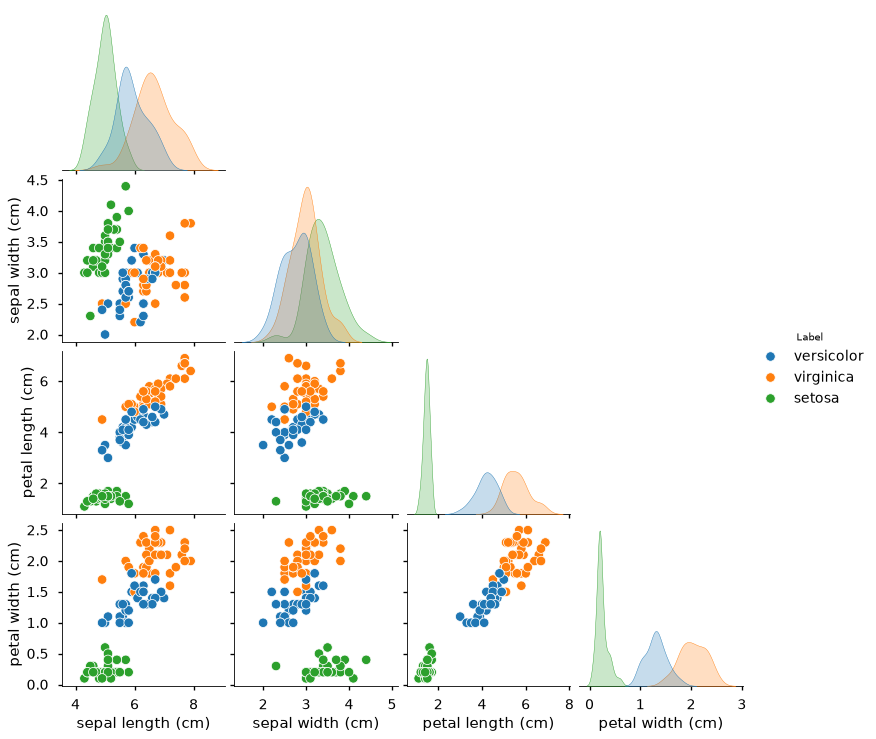

In [5]:
import seaborn as sns
sns.pairplot(iris_train,hue='Label',corner=True,diag_kind='kde')
# sns.pairplot(iris_train,hue='Label',corner=True,diag_kind='hist')

# documentation: https://seaborn.pydata.org/generated/seaborn.pairplot.html. Seaborn is a very useful library for statistical analysis and plotting. Have a look!

In [6]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

X_new = np.array([[5, 2.9, 0, 1]])
prediction = knn.predict(X_new)
print("Prediction:", prediction)
print("Predicted target name:", iris_dataset["target_names"][prediction])
pass;

Prediction: [0]
Predicted target name: ['setosa']


In [7]:
y_pred = knn.predict(X_test)
# X_test
print("Test set predictions:\n", y_pred)
print(y_test)
print("Test set predictions (with labels):\n", [name_map[i] for i in y_pred])
print(y_pred == y_test)
print("Test set score: {:.2f}".format(np.mean(y_pred == y_test))) # explicit computation
print("Test set score: {:.2f}".format(knn.score(X_test, y_test))) # same stuff, different way of computing

Test set predictions:
 [2 1 0 2 0 2 0 1 1 1 2 1 1 1 1 0 1 1 0 0 2 1 0 0 2 0 0 1 1 0 2 1 0 2 2 1 0
 2]
[2 1 0 2 0 2 0 1 1 1 2 1 1 1 1 0 1 1 0 0 2 1 0 0 2 0 0 1 1 0 2 1 0 2 2 1 0
 1]
Test set predictions (with labels):
 ['virginica', 'versicolor', 'setosa', 'virginica', 'setosa', 'virginica', 'setosa', 'versicolor', 'versicolor', 'versicolor', 'virginica', 'versicolor', 'versicolor', 'versicolor', 'versicolor', 'setosa', 'versicolor', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'setosa', 'setosa', 'virginica', 'setosa', 'setosa', 'versicolor', 'versicolor', 'setosa', 'virginica', 'versicolor', 'setosa', 'virginica', 'virginica', 'versicolor', 'setosa', 'virginica']
[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True False]
Test set score: 0.97
Test set score: 0.97


## One issue with *k*-NN: the Curse of dimensionality

- *k*-NN assumes that similar -- i.e. neighboring -- points share similar labels. 
- In high dimensions, this assumption tends to break down: points drawn from a distribution rarely end up close together.
- Illustration: sample points uniformly at random inside the unit cube $[0,1]^d$, and look at how much of the space is needed to capture the $k = 10$ nearest neighbors of a test point.
- Let $\ell$ be the edge length of the smallest hyper-cube containing all $k$ nearest neighbors. Then:
$$
\ell^{d} \approx \frac{k}{n}, \qquad \ell \approx \left( \frac{k}{n} \right)^{1/d}
$$
- With $n = 1000$ and $k = 10$, $\ell$ grows quickly with $d$:

| $d$ | $\ell$ |
|---|---|
| 2 | 0.1 |
| 10 | 0.63 |
| 100 | 0.955 |


- As $d$ grows large, nearly the entire space is needed just to find the 10 nearest neighbors. This undermines the whole point of k-NN: those "neighbors" aren't actually close to the test point, so there's no good reason to expect they share its label.